# UltraVEM-SR — A short tutorial

**UltraVEM-SR** is a 3D super-resolution model for volume electron-microscopy
data (FIB-SEM / SBF-SEM). It takes an **anisotropic, z-undersampled** volume
(typical of SBF-SEM acquisitions where the slice spacing is much coarser than
the in-plane pixel size) and produces an **isotropic high-resolution** volume.

UltraVEM-SR is built on top of [nnU-Net v2](https://github.com/MIC-DKFZ/nnUNet)
with a *residual-prediction head* (the network predicts the residual on top of
a trilinear upsample of the LR input) and can be optionally initialized from
our self-supervised FIB-SEM encoder.

This notebook walks through:

1. **Installation**
2. **Preparing your low-resolution volumes**
3. **Training** a UltraVEM-SR model
4. **Running inference** on new volumes
5. **Visualizing** the super-resolved result

> Training and inference both require a CUDA GPU. The visualization at the end
> works on CPU and uses a pre-computed prediction so you can see the expected
> output without re-running the model.

## 1. Installation

```bash
# Clone our fork of nnU-Net (it carries the custom SR trainer + inference script)
git clone <this-repo>
cd <repo>

# Install dependencies
pip install -e nnUNet/
pip install SimpleITK nibabel tqdm matplotlib

# Tell nnU-Net where to find data / write models
export nnUNet_raw=<your-path>/nnUNet_raw
export nnUNet_preprocessed=<your-path>/nnUNet_preprocessed
export nnUNet_results=<your-path>/nnUNet_results
```

*Optional but recommended* — download our pretrained FIB-SEM encoder
(`mae_checkpoint.pth`) and keep it somewhere local. It is the
self-supervised MAE checkpoint used to warm-start the super-resolver.

## 1b. Sanity-check the pretrained encoder

Before spending GPU time on a full training run, it's worth confirming that the
downloaded MAE checkpoint actually matches the SR trainer's network — same
architecture family, same layer names, same tensor shapes.

We build the exact `ResidualEncoderUNet` that `nnUNetTrainer_SR_x<a>y<b>z<c>_pretrained`
would build from your plans, then load the checkpoint into it with the same
`load_pretrained_weights` helper the trainer calls internally. It reports how
many layers matched by name and shape.

In [ ]:
import json
from nnunetv2.utilities.plans_handling.plans_handler import PlansManager
from nnunetv2.utilities.get_network_from_plans import get_network_from_plans
from nnunetv2.run.load_pretrained_weights import load_pretrained_weights

# Plans/dataset.json produced by step 3's nnUNetv2_plan_and_preprocess call.
PLANS_JSON   = f"{OUT_ROOT.replace('nnUNet_raw', 'nnUNet_preprocessed')}/nnUNetResEncUNetLPlans.json"
DATASET_JSON = f"{OUT_ROOT.replace('nnUNet_raw', 'nnUNet_preprocessed')}/dataset.json"
PRETRAINED_WEIGHTS = "/path/to/mae_checkpoint.pth"

with open(PLANS_JSON) as f:
    plans = json.load(f)
with open(DATASET_JSON) as f:
    dataset_json = json.load(f)

plans_manager  = PlansManager(plans)
config_manager = plans_manager.get_configuration("3d_fullres")
num_channels   = len(dataset_json["channel_names"])

network = get_network_from_plans(
    config_manager.network_arch_class_name,
    config_manager.network_arch_init_kwargs,
    config_manager.network_arch_init_kwargs_req_import,
    num_channels, num_channels,          # SR: 1 channel in, 1 channel out
    allow_init=True, deep_supervision=False,
)
print(f"Target network: {config_manager.network_arch_class_name}")
print(f"Total target params: {sum(p.numel() for p in network.parameters()):,}")

load_pretrained_weights(network, PRETRAINED_WEIGHTS, verbose=True)

Target network: dynamic_network_architectures.architectures.unet.ResidualEncoderUNet
Total target params: 102,348,965

Adaptive pretrained weight loading

  Loaded (exact match):     946
    encoder.stem.convs.0.conv.weight: (32, 1, 3, 3, 3)
    encoder.stem.convs.0.conv.bias: (32,)
    encoder.stem.convs.0.norm.weight: (32,)
    ... and 943 more

  Loaded (kernel adapted):  0
    Strategy: [3,3,3] → [1,3,3] center Z-slice

  Skipped (seg layers):     10
  Skipped (missing):        0

  TOTAL: 946/956 parameters loaded (99.0%)



With the checkpoint loaded, a quick forward pass on a small random volume
confirms the network runs end-to-end (shape in == shape out — the SR trainer's
residual head adds the learned detail on top of a trilinear upsample of the
input, so the raw network itself is shape-preserving; the up-sampling happens
in the data pipeline before the network sees it).

In [ ]:
import torch

network.eval()
with torch.no_grad():
    dummy_input = torch.randn(1, num_channels, 64, 64, 64)
    dummy_output = network(dummy_input)

print(f"input shape:  {tuple(dummy_input.shape)}")
print(f"output shape: {tuple(dummy_output.shape)}")

input shape:  (1, 1, 64, 64, 64)
output shape: (1, 1, 64, 64, 64)


## 2. Prepare your low-resolution volumes

UltraVEM-SR takes **3D anisotropic EM volumes** as input. Each volume should be:

- saved as **`.nii.gz`** (any tool that writes NIfTI works — `SimpleITK`, `nibabel`, …);
- a **single-channel 3D array** with shape `(z, y, x)`;
- intensities normalized to `[0, 1]` (uint8 inputs divided by 255 also work — nnU-Net handles z-score normalization internally);
- the **z-spacing larger than x/y-spacing** (this is the axis the model will up-sample). Set the spacing in the NIfTI header so the model knows the anisotropy ratio.

For training, you also need the **isotropic HR ground-truth** volumes
(downsampled along z during training to create LR/HR pairs).

Below is a minimal helper you can adapt to your own data.

In [ ]:
"""Convert a folder of high-resolution EM volumes into the nnU-Net raw layout
expected by UltraVEM-SR.

Training is self-supervised: supply HIGH-RESOLUTION volumes here. The trainer
subsamples them on the fly to synthesise the low-resolution input, so no paired
acquisition is needed.
"""
import os, json
import numpy as np
import SimpleITK as sitk

SRC_HR_DIR = "/path/to/your/high_resolution_volumes"   # *.tif, *.nii.gz, ...
OUT_ROOT   = "/path/to/your/nnUNet_raw/<DatasetXXX_name>"

# Voxel spacing of the training volumes, in nanometres (x, y, z). Set this to
# your acquisition's true spacing; it is what the scale factors are relative to.
HR_SPACING = (None, None, None)   # e.g. (8.0, 8.0, 8.0)

os.makedirs(f"{OUT_ROOT}/imagesTr", exist_ok=True)
os.makedirs(f"{OUT_ROOT}/labelsTr", exist_ok=True)
os.makedirs(f"{OUT_ROOT}/imagesTs", exist_ok=True)

for idx, fname in enumerate(sorted(os.listdir(SRC_HR_DIR))):
    vol = sitk.ReadImage(os.path.join(SRC_HR_DIR, fname))
    if all(s is not None for s in HR_SPACING):
        vol.SetSpacing(tuple(float(s) for s in HR_SPACING))
    sitk.WriteImage(vol, os.path.join(OUT_ROOT, "imagesTr", f"case_{idx:03d}_0000.nii.gz"))

    # Dummy all-ones label: nnU-Net requires one per case, the SR trainer never reads it.
    label = sitk.GetImageFromArray(np.ones(sitk.GetArrayFromImage(vol).shape, dtype=np.uint8))
    label.CopyInformation(vol)
    sitk.WriteImage(label, os.path.join(OUT_ROOT, "labelsTr", f"case_{idx:03d}.nii.gz"))

with open(f"{OUT_ROOT}/dataset.json", "w") as f:
    json.dump({
        "channel_names": {"0": "EM"},
        "labels": {"background": 0, "foreground": 1},   # placeholder
        "numTraining": len(os.listdir(f"{OUT_ROOT}/imagesTr")),
        "file_ending": ".nii.gz",
    }, f, indent=2)
print("Done.")


**Inference inputs (after training).** Your *actual* anisotropic acquisitions go
into a separate folder. Set their NIfTI spacing so that
`z_spacing / x_spacing` matches the z scale factor of the model you trained, and
the restoration lands on the intended grid.


## 3. Train UltraVEM-SR

```bash
# (a) plan + preprocess — once per dataset
nnUNetv2_plan_and_preprocess -d <DATASET_ID> -c <CONFIGURATION> \
        -pl <PLANNER> --verify_dataset_integrity

# (b) train
nnUNet_SR_SCALE=<sx,sy,sz> nnUNet_SR_EPOCHS=<n> nnUNet_SR_LR=<lr> \
nnUNet_SR_WEIGHT_DECAY=<wd> nnUNet_SR_GRAD_CLIP_NORM=<norm> nnUNet_SR_FREEZE_EPOCHS=<n> \
nnUNet_SR_SSIM_WINDOW_SIZE=<size> nnUNet_SR_WEIGHT_CHARBONNIER=<w> \
nnUNet_SR_WEIGHT_SSIM=<w> nnUNet_SR_WEIGHT_PERCEPTUAL=<w> \
python nnUNet/nnunetv2/run/run_training.py <DATASET_ID> <CONFIGURATION> <FOLD> \
        -tr nnUNetTrainer_SuperResolution \
        -p  <PLANS> \
        -pretrained_weights /path/to/mae_checkpoint.pth   # optional
```

**Configuration.** A single trainer class, `nnUNetTrainer_SuperResolution`, covers
every setting. Nothing is hard-coded and there is no config file — every
hyperparameter below is **required**; training refuses to start until each is set:

| Variable | Meaning |
|---|---|
| `nnUNet_SR_SCALE` | Per-axis scale `"sx,sy,sz"` in image space (or encode it in `-tr`, below) |
| `nnUNet_SR_EPOCHS` | Number of epochs (or encode it in `-tr`, below) |
| `nnUNet_SR_LR` | Initial learning rate |
| `nnUNet_SR_WEIGHT_DECAY` | Optimizer weight decay |
| `nnUNet_SR_GRAD_CLIP_NORM` | Gradient-norm clipping threshold |
| `nnUNet_SR_FREEZE_EPOCHS` | Epochs to hold a pre-trained encoder frozen (`0` disables) |
| `nnUNet_SR_SSIM_WINDOW_SIZE` | Side length, in voxels, of the SSIM pooling window |
| `nnUNet_SR_WEIGHT_CHARBONNIER` | Weight of the Charbonnier (smooth L1) loss term |
| `nnUNet_SR_WEIGHT_SSIM` | Weight of the SSIM loss term (`0` disables it) |
| `nnUNet_SR_WEIGHT_PERCEPTUAL` | Weight of the VGG perceptual loss term (`0` disables it) |

**Scale in the trainer name.** The scale and epoch count may instead be encoded
directly in `-tr`, which is handy for sweeps — these names resolve on demand, so
*any* scale works without editing code:

```
-tr nnUNetTrainer_SR_x1y1z5          scale (1, 1, 5); epochs still required separately
-tr nnUNetTrainer_SR_x2y2z5_100ep    scale (2, 2, 5), 100 epochs
-tr nnUNetTrainer_SR_x1y1z1_5        scale (1, 1, 1.5) — underscore is the decimal point
```

Set the factors to your data's anisotropy ratio (z-spacing / xy-spacing): use
`x1y1z5` for a volume whose z spacing is 5x the in-plane spacing, or `x2y2z2`
for isotropic 2x super-resolution. Precedence is environment variable > trainer
name > error — training refuses to start if neither sets the scale or epochs.
Every other hyperparameter above is always required from the environment.

Warm-starting is **not** part of the trainer name — pass `-pretrained_weights`.

The scale and epoch count are appended to the output folder name, so runs that
differ only in those settings do not overwrite each other:

```
$nnUNet_results/<Dataset>/nnUNetTrainer_SuperResolution__<PLANS>__<CONFIGURATION>__scale-x1y1z5_ep<n>/fold_<FOLD>/checkpoint_final.pth
```

## 4. Run inference

Use the bundled inference script — it handles the residual-on-top-of-interpolation
prediction that the standard `nnUNetv2_predict` does not.

```bash
python nnUNet/nnunetv2/inference/predict_sr.py \
       --input_folder  /path/to/anisotropic_volumes \
       --output_folder /path/to/sr_output \
       --model_folder  $nnUNet_results/<Dataset>/<trainer-folder> \
       --fold <FOLD> \
       --checkpoint <CHECKPOINT_FILE>
```

The per-axis scale is read from the checkpoint, so no flag is needed. If a
checkpoint does not record one, the script stops rather than guessing — a wrong
scale would silently produce a wrongly-sized restoration.

**Useful flags**

| Flag | Meaning |
|---|---|
| `--sr_factors X Y Z` | Override the checkpoint's per-axis scale |
| `--z_scale N` | z-only shorthand, equivalent to `--sr_factors 1 1 N` |
| `--hr_shape X Y Z` | Force an explicit output shape when the LR size does not divide cleanly |
| `--residual_scale` | Scale of the learned residual on top of the interpolated base |
| `--adaptive_blend` | Suppress the residual in flat regions |
| `--tile_step` | Sliding-window overlap (smaller = smoother, slower) |
| `--no_mirror` | Disable test-time mirror augmentation |

Output is one `<case>.nii.gz` per input file, with the target spacing set in the
header.


## 5. Visualize the super-resolved result

Below we load one anisotropic input and its UltraVEM-SR prediction, extract an
**XZ-plane slice** from each (the plane that shows the up-sampled axis), and
display them side by side. The volumes used here come from a previously-run
inference — replace the two paths with your own `--input_folder` /
`--output_folder` files to reproduce on your data.

> This step is CPU-only — no GPU needed.

In [ ]:
import os
import numpy as np
import SimpleITK as sitk
import matplotlib.pyplot as plt

# Replace these two paths with one of your own (input, prediction) pairs.
LR_PATH   = "./example/anisotropic_lr.nii.gz"
PRED_PATH = "./example/super_resolved.nii.gz"

def load(p):
    img = sitk.ReadImage(p)
    return sitk.GetArrayFromImage(img).astype(np.float32), img.GetSpacing()

lr,   lr_sp   = load(LR_PATH)
pred, pred_sp = load(PRED_PATH)
print(f"LR input  : shape={lr.shape}   spacing(xyz)={lr_sp}")
print(f"SR output : shape={pred.shape}  spacing(xyz)={pred_sp}")

# z-anisotropy ratio (e.g. 5 for a 5x z-undersampled volume).
z_factor = round(lr_sp[2] / lr_sp[0])

# Pick an XZ slice (fixed y) — z is the up-sampled axis, so this is the plane
# where the improvement is most visible.
y = pred.shape[1] // 2
xz_lr   = lr[:,   y, :]   # native (z_lr, x) — short / wide
xz_pred = pred[:, y, :]   # (z_hr, x) — square

# Shared intensity window.
vmin, vmax = np.percentile(xz_pred, [1, 99])

# Draw both panels at the same physical extent by setting `aspect=z_factor` on
# the LR panel (each LR z-pixel is z_factor times taller than an x-pixel in
# physical units).  Matplotlib then displays the LR stretched to the same
# height as the HR while keeping the data un-touched.
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(xz_lr,   cmap="gray", vmin=vmin, vmax=vmax,
               aspect=z_factor, interpolation="bilinear")
axes[0].set_title(f"Input (anisotropic LR, {z_factor}x z-undersampled)",
                  fontsize=12, fontweight="bold")
axes[1].imshow(xz_pred, cmap="gray", vmin=vmin, vmax=vmax,
               aspect=1.0, interpolation="none")
axes[1].set_title("UltraVEM-SR output (isotropic HR)",
                  fontsize=12, fontweight="bold")
for ax in axes:
    ax.set_xlabel("x"); ax.set_ylabel("z")
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()
plt.show()

LR input  : shape=(103, 512, 512)   spacing(xyz)=(8.0, 8.0, 40.0)
SR output : shape=(512, 512, 512)  spacing(xyz)=(8.0, 8.0, 8.0)


**Expected output**

<table>
<tr>
<td align="center" valign="middle"><b>Input (anisotropic LR, native aspect)</b><br>
<sub>103 z-slices x 512 in-plane &mdash; appears short and wide</sub><br>
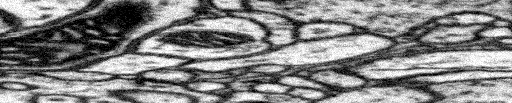</td>
<td align="center" valign="middle"><b>UltraVEM-SR output (isotropic HR)</b><br>
<sub>512 z-slices x 512 in-plane</sub><br>
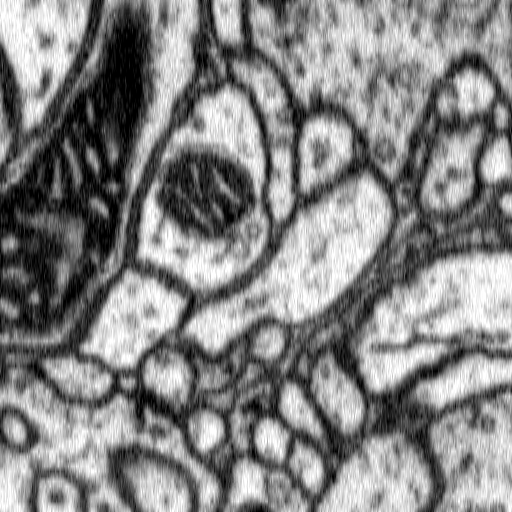</td>
</tr>
</table>

The input has 5x fewer z-slices than in-plane samples, so the same volume
appears as a short, wide strip when drawn at 1:1 pixel aspect. UltraVEM-SR
fills in the missing z-slices, producing an isotropic HR volume in which
membranes and organelle boundaries are sharp along the z-axis as well as
in-plane.

## Summary

An end-to-end UltraVEM-SR workflow:

1. organize high-resolution `.nii.gz` volumes in the nnU-Net raw layout,
2. `nnUNetv2_plan_and_preprocess` once per dataset,
3. `run_training.py -tr nnUNetTrainer_SuperResolution`, configured through the
   `nnUNet_SR_*` variables (or a `nnUNetTrainer_SR_x..y..z..` trainer name),
4. `predict_sr.py` on your anisotropic acquisitions,
5. inspect the result in any NIfTI viewer, or with the snippet above.
